# 34 · EOxElements Jupyter: Python-controlled maps

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** create a real EOxMap widget in JupyterLite; link layer controls; change bands from Python.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=34_eopf_eox_widgets.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


**Reproducibility record.** Project: Earth in the Browser; author: course contributors;
email/organization: not supplied. Created/updated: 2026-11-21. Input: `data/eopf/`;
outputs: the figures and objects below (exports are named explicitly). Python, NumPy and
Matplotlib; SQLite where used. Initial EOPF teaching release. The acquisition is a
convenience example, not a representative sample. Missing values remain missing.

![EOPF workflow from discovery to direct maps, quality-aware analysis and server processing](assets/eopf-workflow.svg)
## 1. Connect Python traits to a real map component

The [EOxElements-Jupyter guide](https://explorer.eopf.copernicus.eu/software-services/EOxElements-Jupyter/)
maps Python classes to EOxElements web components through **anywidget**. This lesson
uses `ipyeoxelements==1.1.0` with pinned map and layer-control releases. JupyterLite
installs the bundled pure-Python wheel; its JavaScript components load from jsDelivr.
The first widget start needs internet and WebGL. The Book strips live widget state
and retains the reference plot. Re-run in JupyterLite for the actual controls.

In [2]:
from eopf import install_widget, load_eopf, map_layers, SITE, rgb, qualify_widget_urls
await install_widget()
from ipyeoxelements import EOxMap, EOxLayercontrol
from ipywidgets import HBox, VBox, Layout, Dropdown
import sys
d=load_eopf()
# Browser-relative URL also works when Pages is served below a project path.
url='../../data/eopf/classroom.zarr/' if sys.platform=='emscripten' else SITE+'/data/eopf/classroom.zarr/'
eo_map=EOxMap(version='2.10.0',id='classroom-eopf-map',
    layers=map_layers(url),center=[14.08,41.07],zoom=11,
    layout=Layout(width='100%',height='450px'))
qualify_widget_urls(eo_map)  # Convert relative URLs in the frontend document context.
control=EOxLayercontrol(version='1.10.1',for_='#classroom-eopf-map')
control._esm=control._esm.replace('!== null','!= null')  # Skip unset optional traits.
choice=Dropdown(options=['True color','False color'],description='Bands:')
def set_bands(change):
    bands=('b04','b03','b02') if change['new']=='True color' else ('b08','b04','b03')
    eo_map.layers=map_layers(url,bands)
choice.observe(set_bands,names='value')
display(VBox([choice,eo_map,control]))

## 2. Trace a Python → widget update

Use the dropdown. The observer replaces the layer configuration, anywidget sends
the changed trait, and `<eox-map>` updates its WebGL layer. The layer-control targets
the map's unique ID. Do not reuse that ID for several displayed widgets.
The following change is visible in the map; the assert checks Python state only.
Browser tests additionally inspect the rendered component and its canvas.

Python source configuration: {'type': 'GeoZarr', 'url': 'https://jltobias.github.io/JupyterLite-zarr-sql-views/data/eopf/classroom.zarr/', 'bands': ['b08', 'b04', 'b03']}


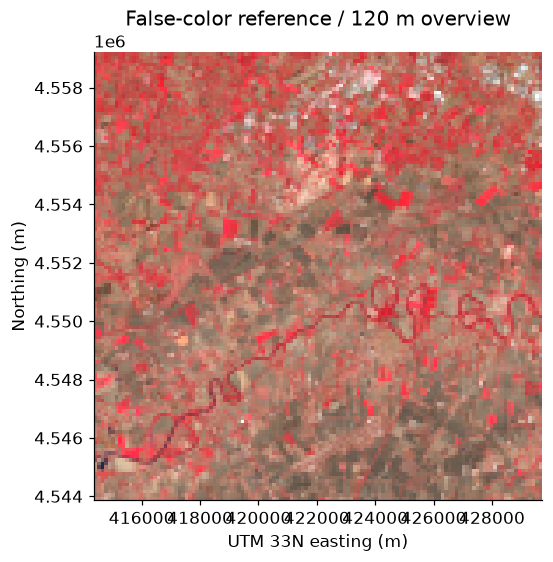

In [3]:
choice.value='False color'
assert eo_map.layers[0]['source']['bands']==['b08','b04','b03']
print('Python source configuration:',eo_map.layers[0]['source'])
# Independent static reference for readers of the Book.
fig,ax=plt.subplots(figsize=(6,5),layout='constrained')
ax.imshow(rgb(d,('b08','b04','b03')),extent=[d['provenance']['bounds'][i] for i in [0,2,1,3]])
ax.set(title='False-color reference / 120 m overview',xlabel='UTM 33N easting (m)',ylabel='Northing (m)')
plt.show()

## 3. Extend to a globe and a story

The official [3D globe tutorial](https://explorer.eopf.copernicus.eu/software-services/eoxelements/globe)
and [EOxElements examples](https://explorer.eopf.copernicus.eu/software-services/eoxelements/)
show the globe plugin, terrain and storytelling components. Try the official globe
with its documented mosaic source; the small classroom window alone is not global
terrain. Distinguish a 3D camera from measured height, and distinguish a story's
annotations from observations. Compare with the course's existing LexCube lessons
for a genuinely time-indexed 3D data volume.

**Troubleshooting:** a blank widget can be a CDN/WebGL failure even when the Python
cell succeeds. Use notebook 33's separate map page or the static reference while
checking browser errors. Do not interpret a blank canvas as missing satellite data.

## Try it yourself

Create a second independent map with a different ID and compare true and false color. Explain which state is shared and which is independent.

## Check your reasoning

Each map has its own layer configuration and ID. Reusing a layer-control selector may control the wrong map; copying arrays does not create a second acquisition.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [EOPF Sentinel Zarr Explorer](https://explorer.eopf.copernicus.eu/), funded by ESA through the Copernicus Space Component programme; EOX, Development Seed and project contributors.
- [Copernicus Sentinel data legal notice](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice): contains modified Copernicus Sentinel data (2026). EOPF processing; course subset and repackaging.
- [Recorded source objects, checksums and transformations](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/eopf/provenance.json). One 128 × 128 window of the upstream 120 m averaged overview, acquired 2026-09-28.
- [EOxElements-Jupyter source](https://github.com/EOX-A/EOxElements-Jupyter), EOX and contributors; MIT notice bundled with the unmodified wheel.
- [anywidget documentation](https://anywidget.dev/), MIT.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [4]:
print('LESSON COMPLETE: 34_eopf_eox_widgets')

LESSON COMPLETE: 34_eopf_eox_widgets
